In [25]:
# Step 1. Import libraries and load cleaned dataset

import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

PROJECT_ROOT = Path.cwd().parent
DATA_PROCESSED = PROJECT_ROOT / "data_processed"
OUTPUTS = PROJECT_ROOT / "outputs"

OUTPUTS.mkdir(exist_ok=True)

df = pd.read_csv(DATA_PROCESSED / "stroke_risk_panel_clean.csv")

print("Shape:", df.shape)
df.head()

Shape: (44, 7)


,PHU,Year,stroke_hosp_rate,smoking_rate,no_pa_minutes_rate,low_fv_rate,heavy_drinking_rate
0,Algoma Public Health,2016,127.8,26.2,19.0,73.2,55.1
1,Algoma Public Health,2017,131.1,26.2,19.0,73.2,55.1
2,Chatham-Kent Public Health,2016,146.7,19.0,20.6,72.7,49.5
3,Chatham-Kent Public Health,2017,139.0,19.0,20.6,72.7,49.5
4,City of Hamilton Public Health Services,2016,138.5,15.3,17.3,75.3,43.9


In [26]:
# Step 2. Basic overview

print("Dataset info:")
print(df.info())

print("\nYears available:")
print(sorted(df["Year"].unique()))

print("\nNumber of PHUs:")
print(df["PHU"].nunique())

print("\nPHU-Year rows:")
print(df[["PHU", "Year"]].head(10))

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44 entries, 0 to 43
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   PHU                  44 non-null     object 
 1   Year                 44 non-null     int64  
 2   stroke_hosp_rate     44 non-null     float64
 3   smoking_rate         44 non-null     float64
 4   no_pa_minutes_rate   44 non-null     float64
 5   low_fv_rate          44 non-null     float64
 6   heavy_drinking_rate  44 non-null     float64
dtypes: float64(5), int64(1), object(1)
memory usage: 2.5+ KB
None

Years available:
[np.int64(2016), np.int64(2017)]

Number of PHUs:
22

PHU-Year rows:
                                       PHU  Year
0                     Algoma Public Health  2016
1                     Algoma Public Health  2017
2               Chatham-Kent Public Health  2016
3               Chatham-Kent Public Health  2017
4  City of Hamilton Public Health S

In [27]:
# Step 3. Descriptive statistics

numeric_cols = [
    "stroke_hosp_rate",
    "smoking_rate",
    "no_pa_minutes_rate",
    "low_fv_rate",
    "heavy_drinking_rate"
]

summary_stats = df[numeric_cols].describe().T
summary_stats["median"] = df[numeric_cols].median()
summary_stats["variance"] = df[numeric_cols].var()

summary_stats

,count,mean,std,min,25%,50%,75%,max,median,variance
stroke_hosp_rate,44.0,123.365909,21.081513,86.7,110.825,120.65,136.425,187.6,120.65,444.430206
smoking_rate,44.0,15.986364,4.449645,7.9,14.600,15.65,19.000,26.2,15.65,19.799345
no_pa_minutes_rate,44.0,19.400000,3.254764,13.5,17.000,19.20,22.400,26.0,19.20,10.593488
low_fv_rate,44.0,72.377273,2.604278,66.8,71.300,72.60,74.200,77.5,72.60,6.782262
heavy_drinking_rate,44.0,48.822727,6.593297,33.1,46.300,50.00,54.000,56.1,50.00,43.471564


In [28]:
# Step 4. Year wise descriptive statistics

year_summary = df.groupby("Year")[numeric_cols].agg(["mean", "median", "std", "min", "max"])
year_summary

stroke_hosp_rate                                 smoking_rate                             no_pa_minutes_rate                              low_fv_rate                              heavy_drinking_rate                             
                 mean  median        std   min    max         mean median       std  min   max               mean median       std   min   max        mean median       std   min   max                mean median       std   min   max
Year                                                                                                                                                                                                                                    
2016       122.195455  117.35  21.997218  86.7  187.6    15.986364  15.65  4.502306  7.9  26.2               19.4   19.2  3.293283  13.5  26.0   72.377273   72.6  2.635099  66.8  77.5           48.822727   50.0  6.671327  33.1  56.1
2017       124.536364  124.60  20.573667  90.0  168.7    15.986364  15.65  4.502306  7.9  26.2               19.4   19.2  3.293283  13.5  26.0   72.377273   72.6  2.635099  66.8  77.5           48.822727   50.0  6.671327  33.1  56.1

In [29]:
# Step 5. Save descriptive statistics

summary_stats.to_csv(DATA_PROCESSED / "eda_summary_statistics.csv")
year_summary.to_csv(DATA_PROCESSED / "eda_yearwise_summary.csv")

print("Saved summary files.")

Saved summary files.


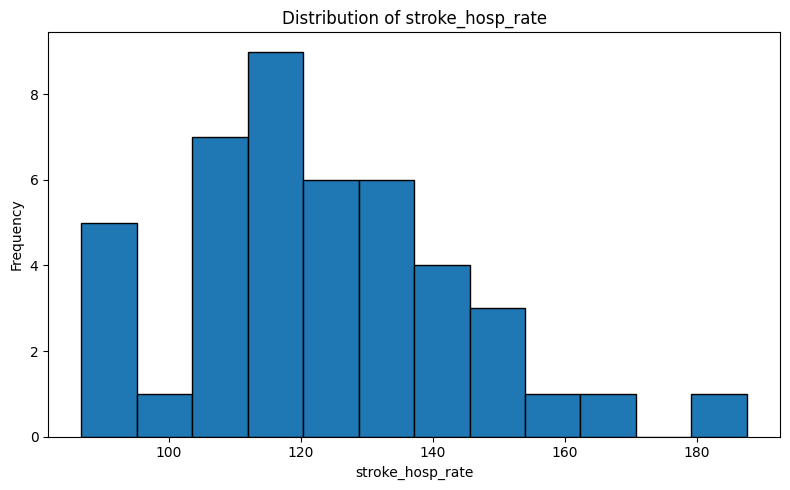

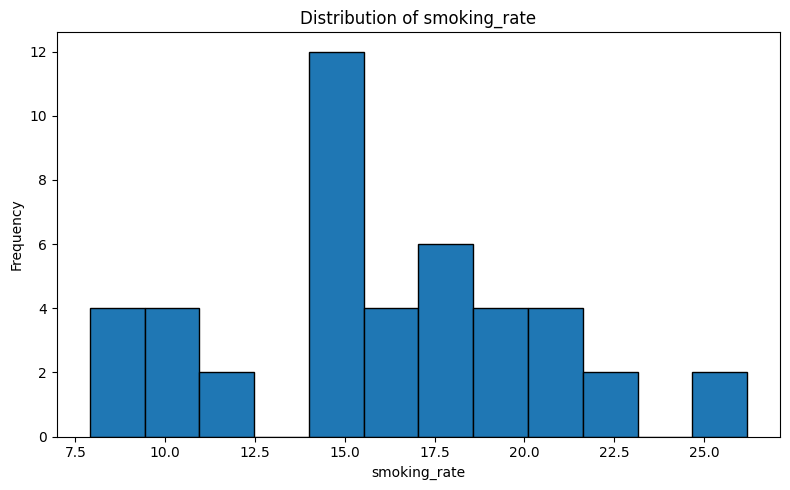

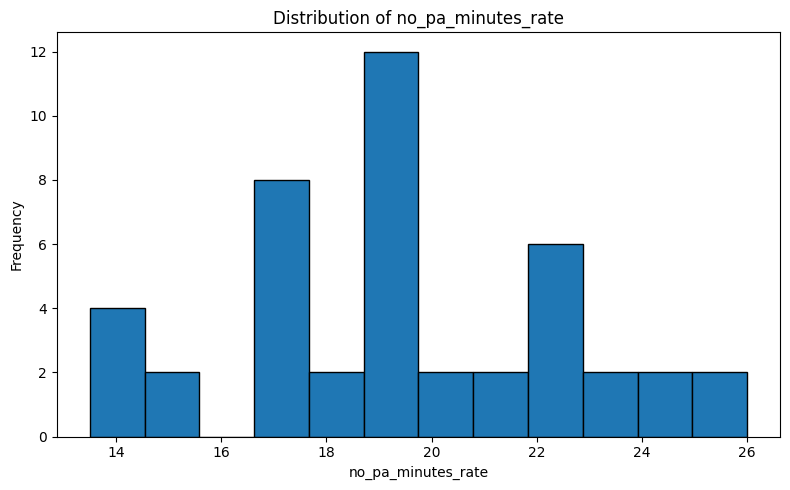

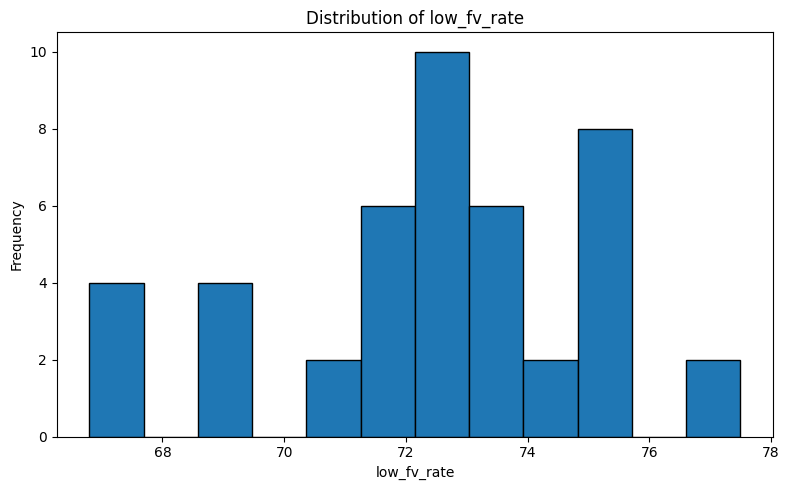

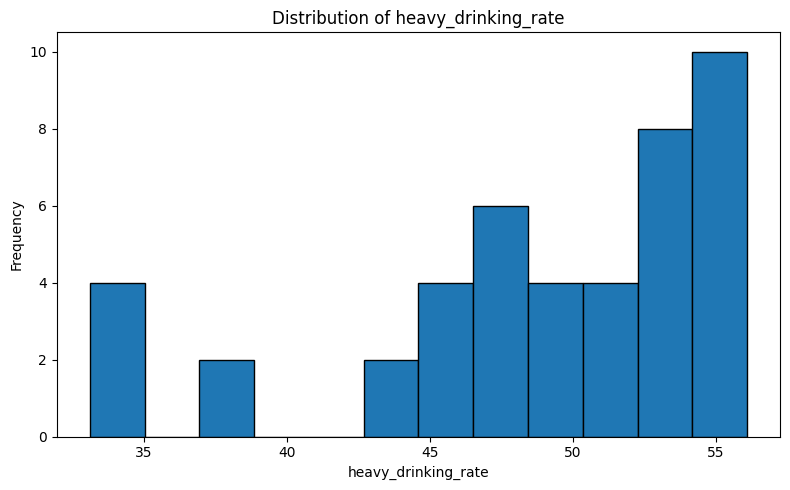

In [30]:
# Step 6. Histograms for each variable

for col in numeric_cols:
    plt.figure(figsize=(8, 5))
    plt.hist(df[col], bins=12, edgecolor="black")
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.savefig(OUTPUTS / f"{col}_histogram.png")
    plt.show()

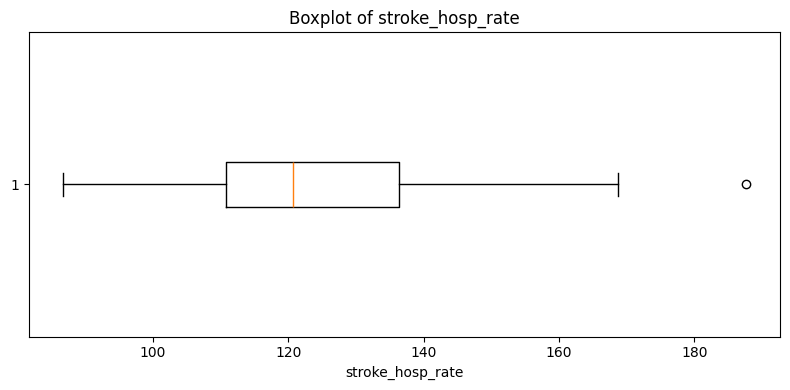

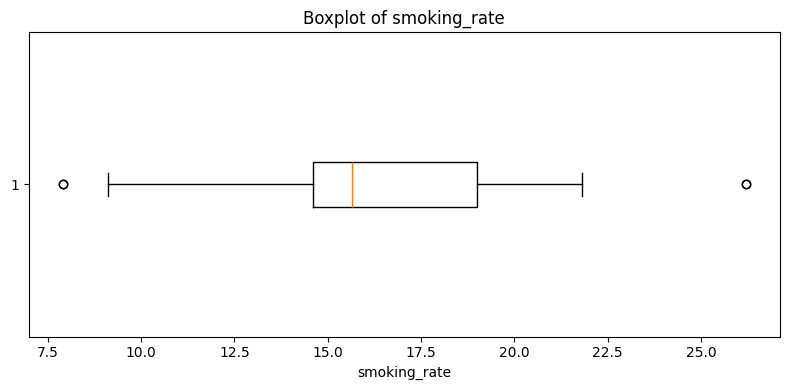

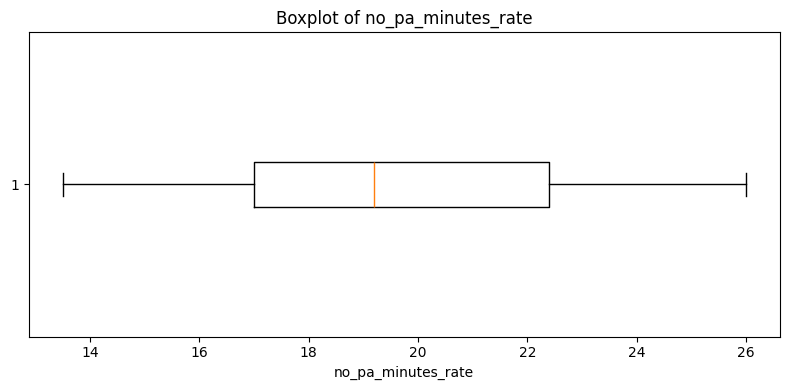

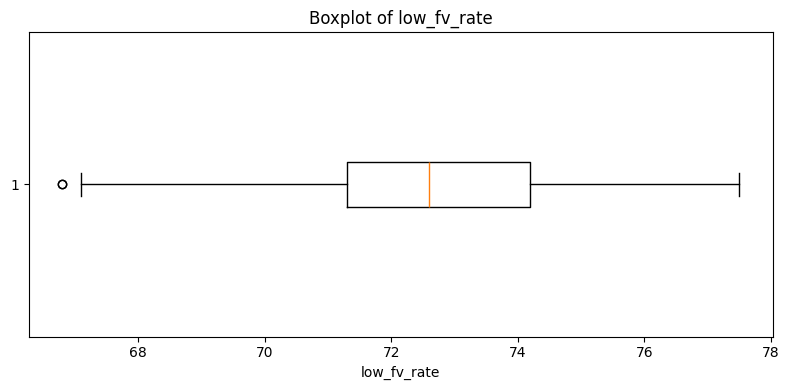

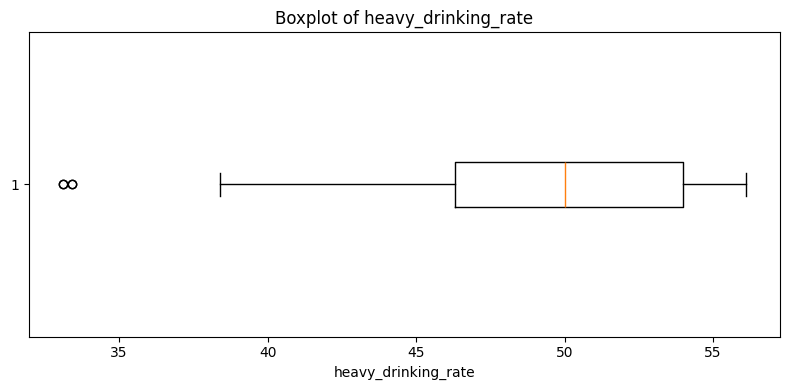

In [31]:
# Step 7. Boxplots for each variable

for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    plt.boxplot(df[col], vert=False)
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.savefig(OUTPUTS / f"{col}_boxplot.png")
    plt.show()

In [32]:
# Step 8. Correlation matrix

corr = df[numeric_cols].corr()
corr

,stroke_hosp_rate,smoking_rate,no_pa_minutes_rate,low_fv_rate,heavy_drinking_rate
stroke_hosp_rate,1.000000,0.614514,-0.334948,0.192349,0.425241
smoking_rate,0.614514,1.000000,-0.296684,0.287356,0.780763
no_pa_minutes_rate,-0.334948,-0.296684,1.000000,0.294720,-0.465948
low_fv_rate,0.192349,0.287356,0.294720,1.000000,-0.020475
heavy_drinking_rate,0.425241,0.780763,-0.465948,-0.020475,1.000000


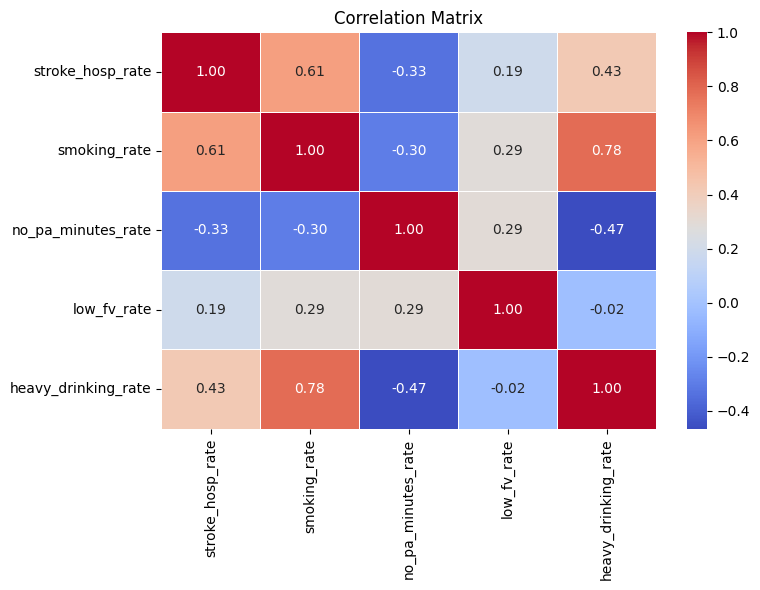

In [33]:
# Step 9. Correlation heatmap

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.savefig(OUTPUTS / "correlation_heatmap.png")
plt.show()

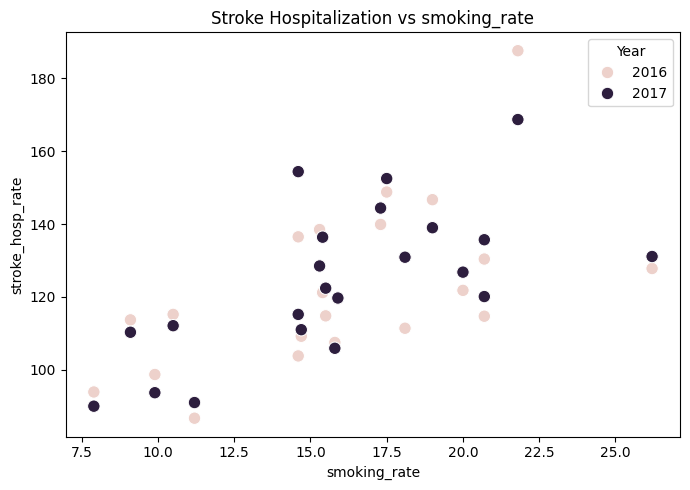

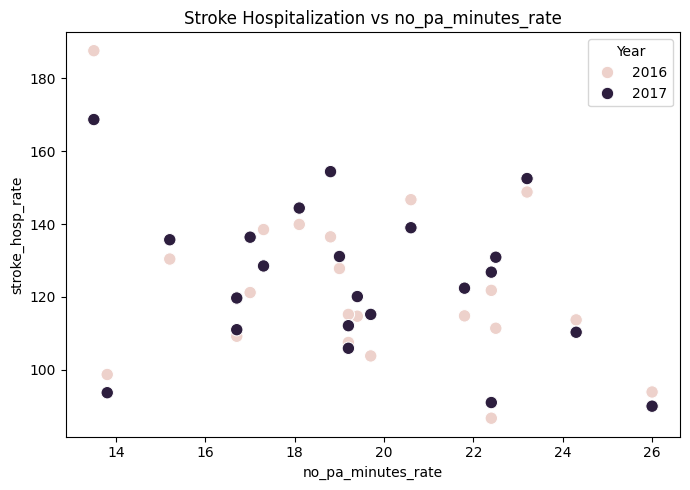

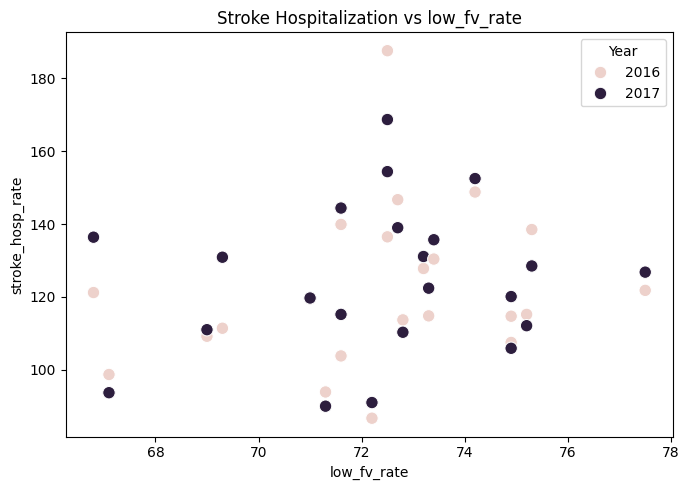

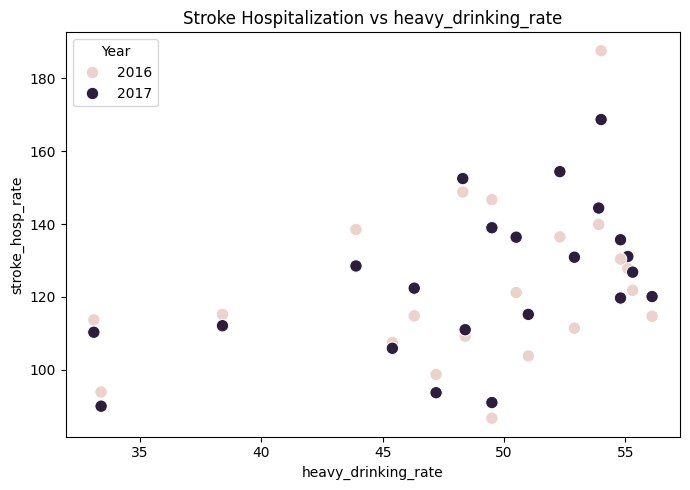

In [34]:
# Step 10. Scatter plots of each risk factor vs stroke hospitalization

risk_cols = [
    "smoking_rate",
    "no_pa_minutes_rate",
    "low_fv_rate",
    "heavy_drinking_rate"
]

for col in risk_cols:
    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=df, x=col, y="stroke_hosp_rate", hue="Year", s=80)
    plt.title(f"Stroke Hospitalization vs {col}")
    plt.xlabel(col)
    plt.ylabel("stroke_hosp_rate")
    plt.tight_layout()
    plt.savefig(OUTPUTS / f"scatter_stroke_vs_{col}.png")
    plt.show()

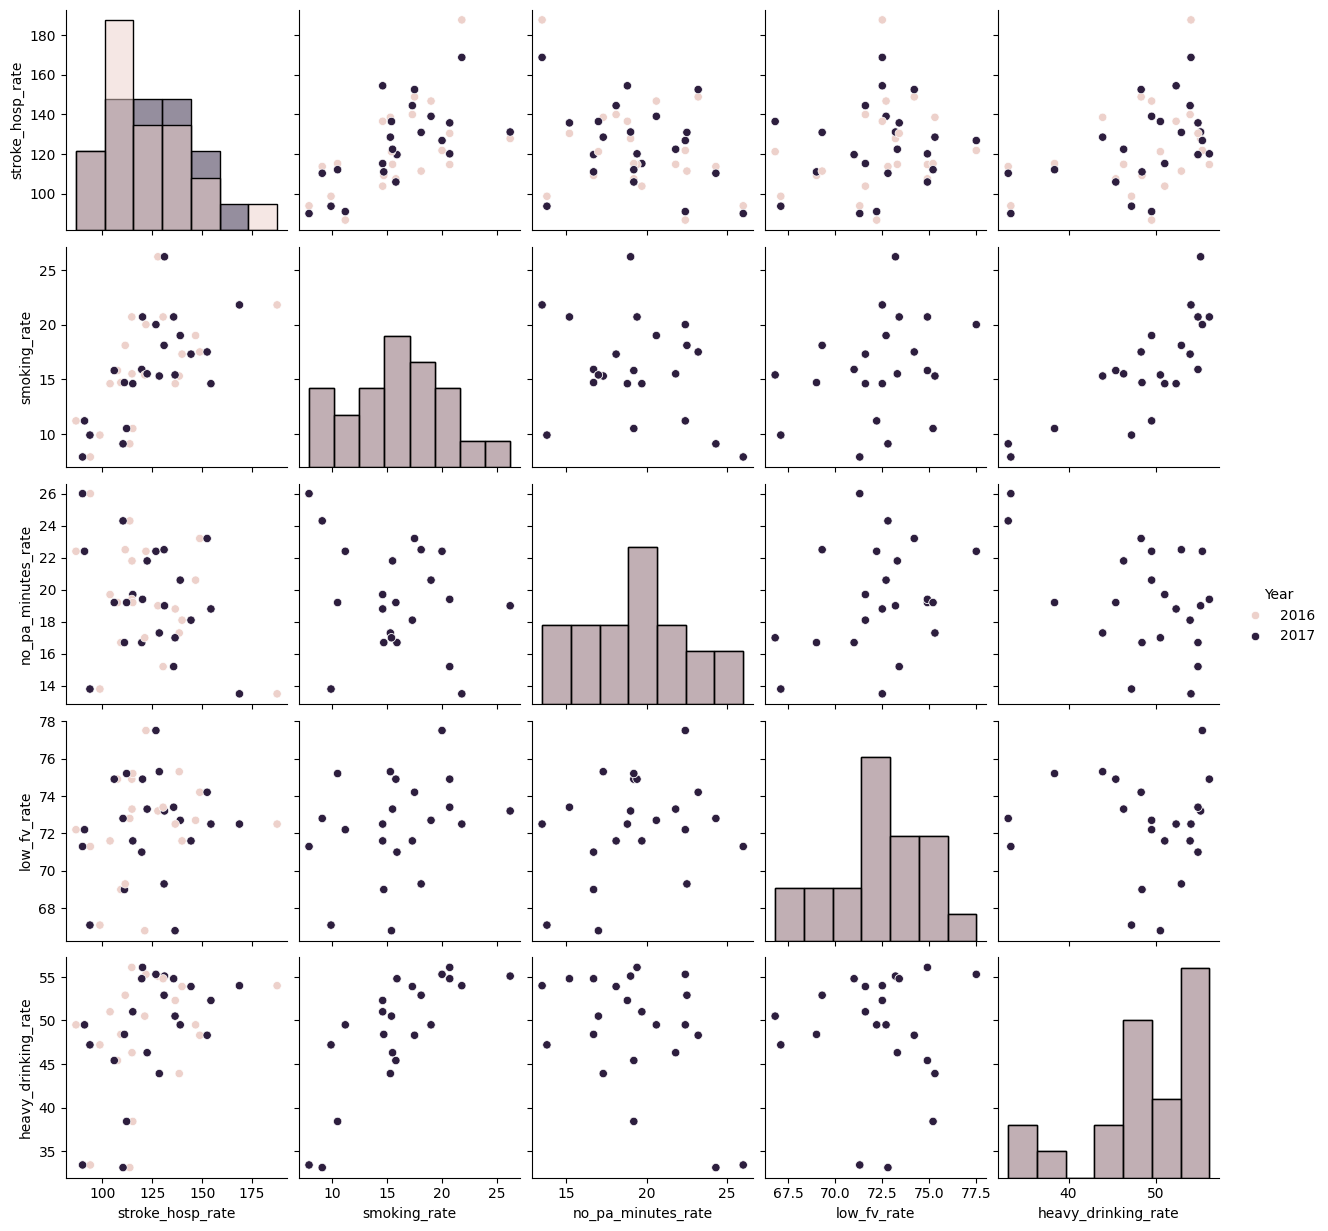

In [35]:
# Step 11. Pairplot

sns.pairplot(
    df[numeric_cols + ["Year"]],
    hue="Year",
    diag_kind="hist"
)
plt.savefig(OUTPUTS / "pairplot_variables.png")
plt.show()

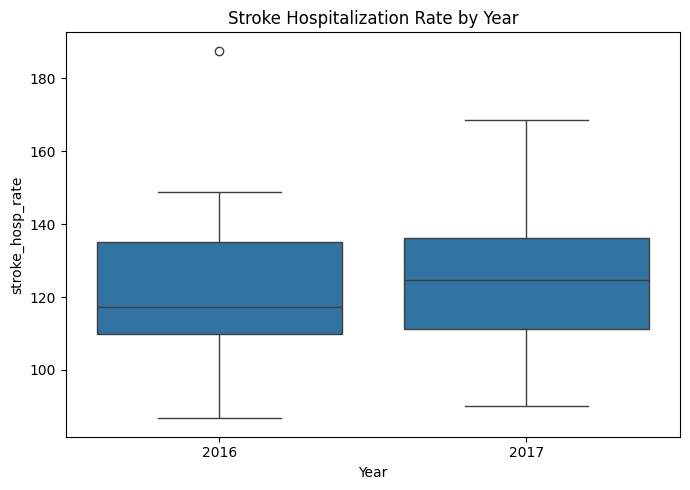

In [36]:
# Step 12. Compare hospitalization rates by year

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Year", y="stroke_hosp_rate")
plt.title("Stroke Hospitalization Rate by Year")
plt.tight_layout()
plt.savefig(OUTPUTS / "stroke_rate_by_year_boxplot.png")
plt.show()

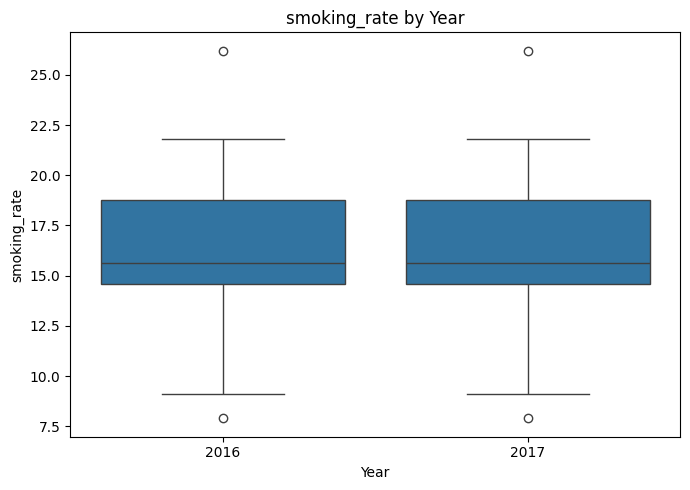

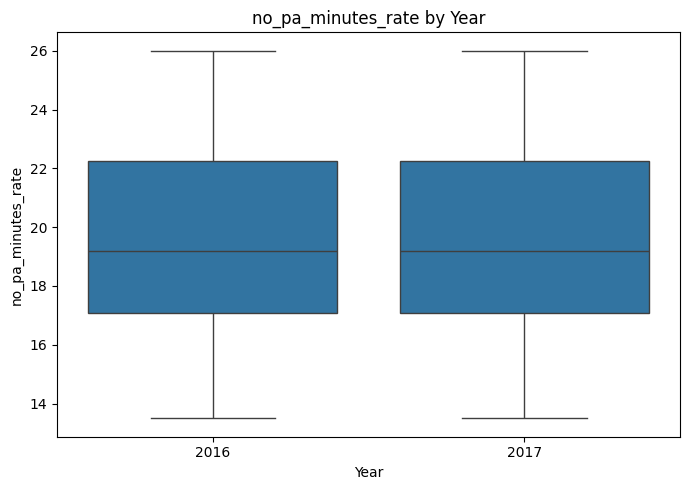

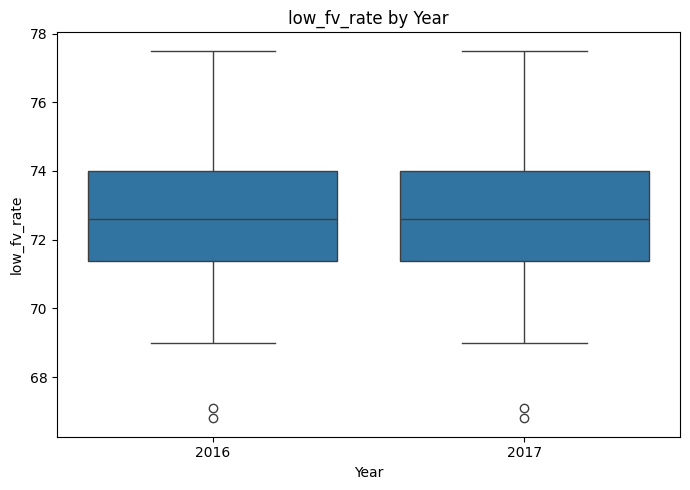

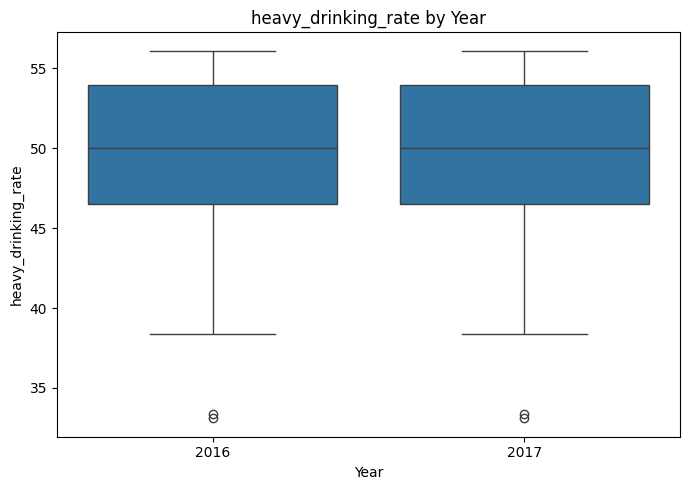

In [37]:
# Step 13. Compare each risk factor by year

for col in risk_cols:
    plt.figure(figsize=(7, 5))
    sns.boxplot(data=df, x="Year", y=col)
    plt.title(f"{col} by Year")
    plt.tight_layout()
    plt.savefig(OUTPUTS / f"{col}_by_year_boxplot.png")
    plt.show()

In [38]:
# Step 14. Mean values by year

mean_by_year = df.groupby("Year")[numeric_cols].mean()
mean_by_year

,stroke_hosp_rate,smoking_rate,no_pa_minutes_rate,low_fv_rate,heavy_drinking_rate
Year,,,,,
2016,122.195455,15.986364,19.4,72.377273,48.822727
2017,124.536364,15.986364,19.4,72.377273,48.822727


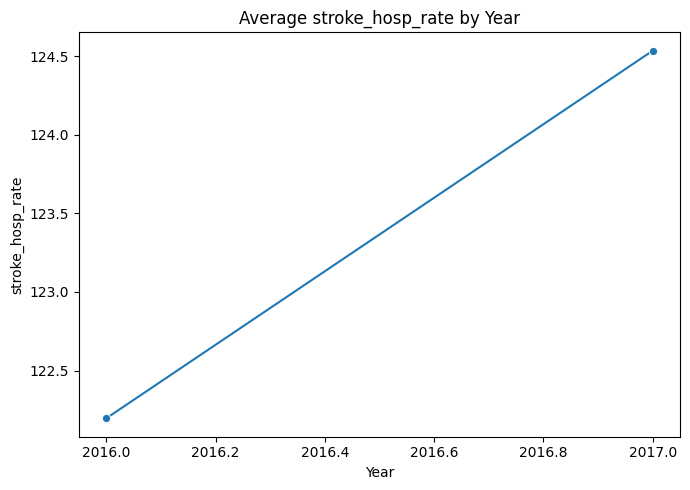

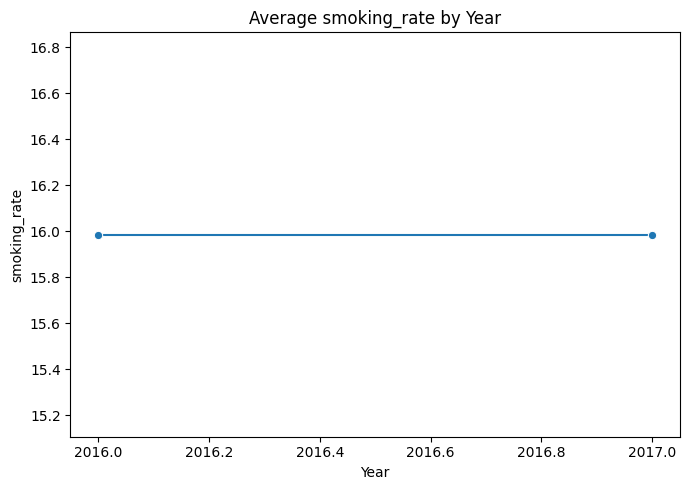

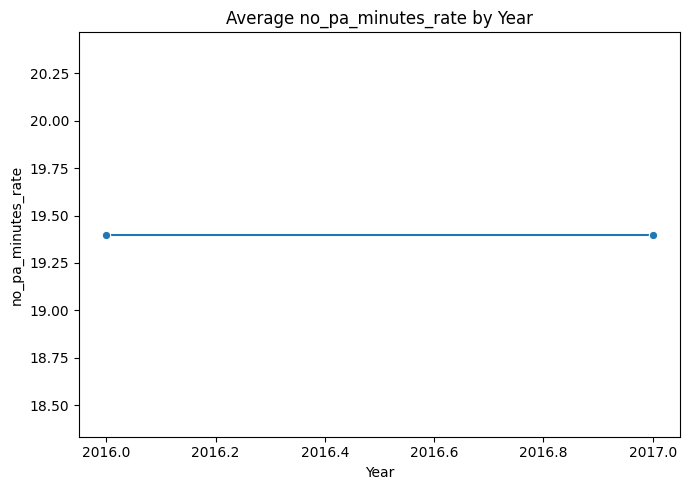

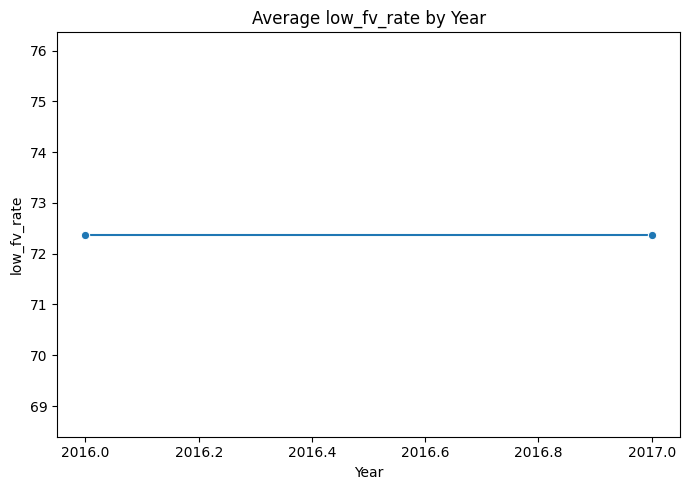

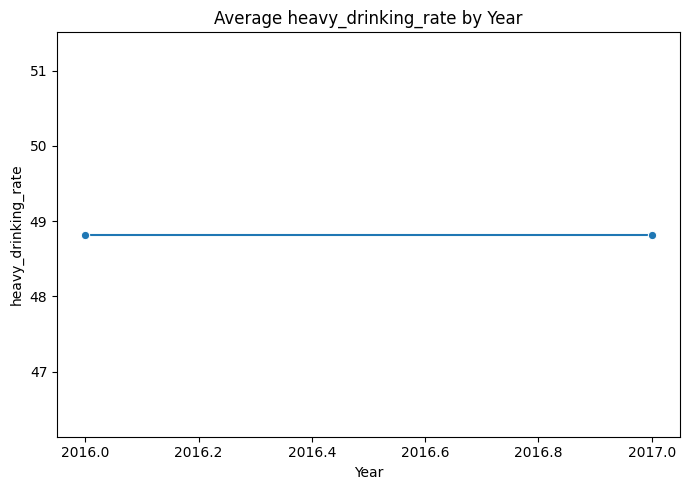

In [39]:
# Step 15. Line plot of mean values by year

for col in numeric_cols:
    plt.figure(figsize=(7, 5))
    sns.lineplot(data=df.groupby("Year")[col].mean().reset_index(), x="Year", y=col, marker="o")
    plt.title(f"Average {col} by Year")
    plt.tight_layout()
    plt.savefig(OUTPUTS / f"mean_{col}_by_year.png")
    plt.show()

In [40]:
# Step 16. Top PHUs with highest average stroke hospitalization

top_phus = (
    df.groupby("PHU")["stroke_hosp_rate"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_phus

,PHU,stroke_hosp_rate
0,Northwestern Health Unit,178.15
1,Southwestern Public Health,150.65
2,Huron Perth Public Health,145.45
3,Chatham-Kent Public Health,142.85
4,Thunder Bay District Health Unit,142.15
5,City of Hamilton Public Health Services,133.50
6,Renfrew County and District Health Unit,133.05
7,Algoma Public Health,129.45
8,Wellington-Dufferin-Guelph Public Health,128.80
9,Lambton Public Health,124.30


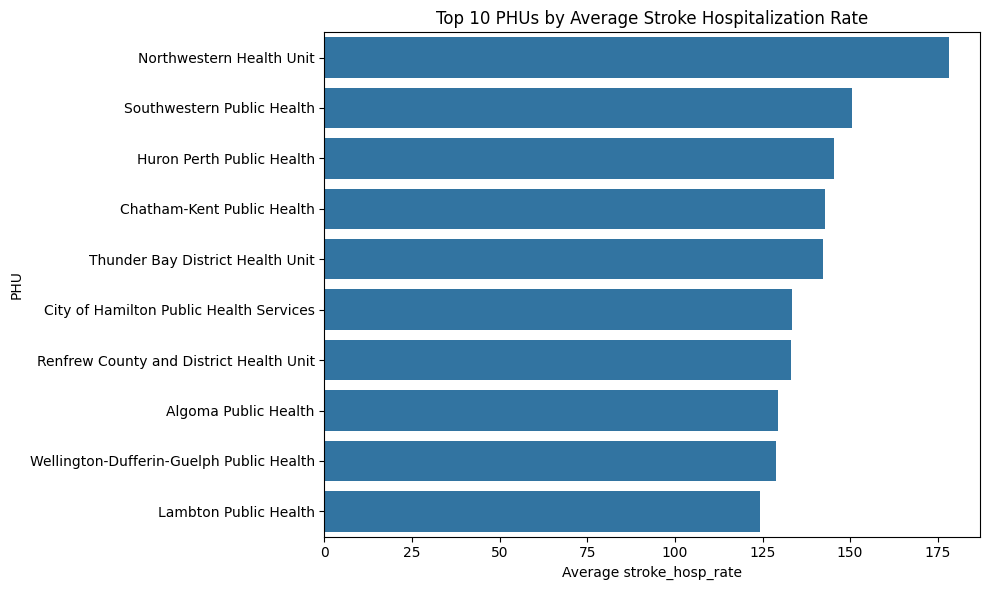

In [41]:
# Step 17. Bar chart of top PHUs

plt.figure(figsize=(10, 6))
sns.barplot(data=top_phus, x="stroke_hosp_rate", y="PHU")
plt.title("Top 10 PHUs by Average Stroke Hospitalization Rate")
plt.xlabel("Average stroke_hosp_rate")
plt.ylabel("PHU")
plt.tight_layout()
plt.savefig(OUTPUTS / "top10_phus_stroke_rate.png")
plt.show()

In [42]:
# Step 18. Bottom PHUs with lowest average stroke hospitalization

bottom_phus = (
    df.groupby("PHU")["stroke_hosp_rate"]
    .mean()
    .sort_values(ascending=True)
    .head(10)
    .reset_index()
)

bottom_phus

,PHU,stroke_hosp_rate
0,Halton Region Public Health,88.85
1,York Region Public Health,91.95
2,Ottawa Public Health,96.20
3,Niagara Region Public Health,106.70
4,Durham Region Health Department,109.50
5,Middlesex-London Health Unit,110.10
6,Peel Public Health,112.00
7,Toronto Public Health,113.65
8,Public Health Sudbury & Districts,117.40
9,Windsor-Essex County Health Unit,118.60


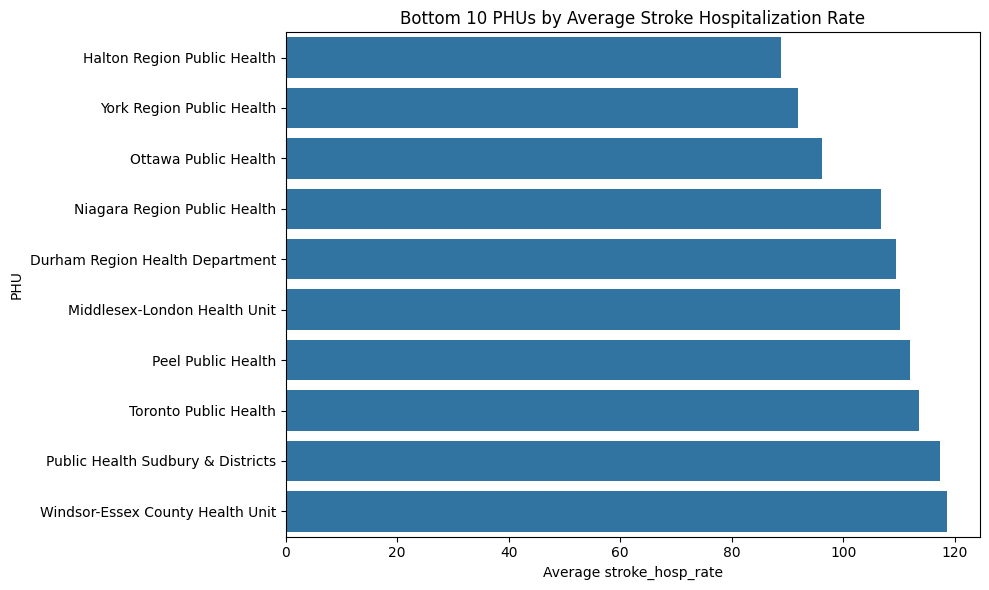

In [43]:
# Step 19. Bar chart of lowest PHUs

plt.figure(figsize=(10, 6))
sns.barplot(data=bottom_phus, x="stroke_hosp_rate", y="PHU")
plt.title("Bottom 10 PHUs by Average Stroke Hospitalization Rate")
plt.xlabel("Average stroke_hosp_rate")
plt.ylabel("PHU")
plt.tight_layout()
plt.savefig(OUTPUTS / "bottom10_phus_stroke_rate.png")
plt.show()

In [44]:
# Step 20. Average risk factor profile by PHU

phu_profile = df.groupby("PHU")[risk_cols + ["stroke_hosp_rate"]].mean()
phu_profile.head()

,smoking_rate,no_pa_minutes_rate,low_fv_rate,heavy_drinking_rate,stroke_hosp_rate
PHU,,,,,
Algoma Public Health,26.2,19.0,73.2,55.1,129.45
Chatham-Kent Public Health,19.0,20.6,72.7,49.5,142.85
City of Hamilton Public Health Services,15.3,17.3,75.3,43.9,133.50
Durham Region Health Department,14.6,19.7,71.6,51.0,109.50
Halton Region Public Health,11.2,22.4,72.2,49.5,88.85


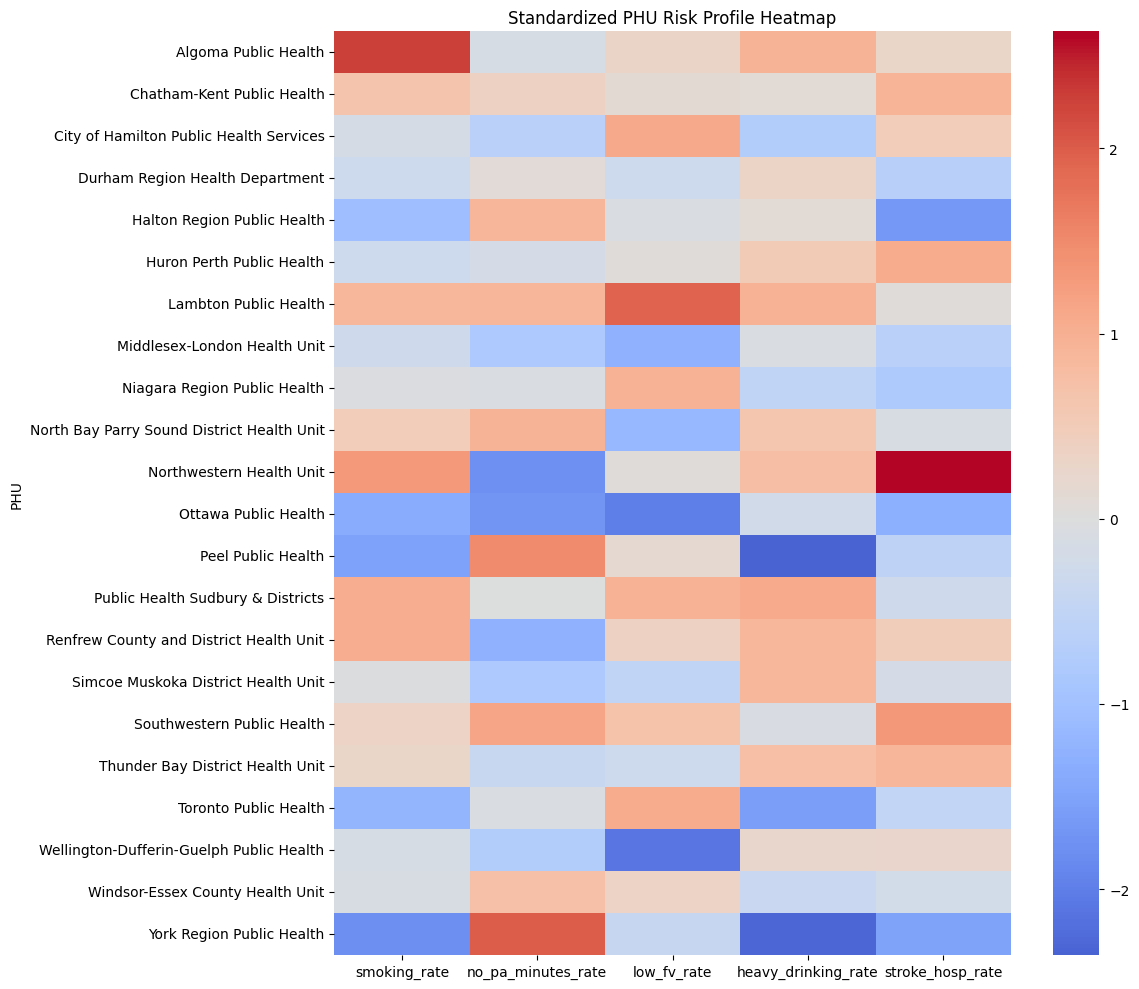

In [45]:
# Step 21. Standardized heatmap by PHU

phu_profile_scaled = (phu_profile - phu_profile.mean()) / phu_profile.std()

plt.figure(figsize=(12, 10))
sns.heatmap(phu_profile_scaled, cmap="coolwarm", center=0)
plt.title("Standardized PHU Risk Profile Heatmap")
plt.tight_layout()
plt.savefig(OUTPUTS / "phu_risk_profile_heatmap.png")
plt.show()

In [46]:
# Step 22. Save EDA tables

corr.to_csv(DATA_PROCESSED / "eda_correlation_matrix.csv")
mean_by_year.to_csv(DATA_PROCESSED / "eda_mean_by_year.csv")
top_phus.to_csv(DATA_PROCESSED / "eda_top_phus.csv", index=False)
bottom_phus.to_csv(DATA_PROCESSED / "eda_bottom_phus.csv", index=False)

print("EDA tables saved.")

EDA tables saved.


In [47]:
# Step 23. EDA interpretation helper

print("Correlation with stroke hospitalization:")
print(corr["stroke_hosp_rate"].sort_values(ascending=False))

Correlation with stroke hospitalization:
stroke_hosp_rate       1.000000
smoking_rate           0.614514
heavy_drinking_rate    0.425241
low_fv_rate            0.192349
no_pa_minutes_rate    -0.334948
Name: stroke_hosp_rate, dtype: float64
